## Logistic Regression

AZ: Describe the model WIP!

The model is trained and evaluated in the following steps:

1. **Features and target:** `Gallstone Status` is the target for the moddel. All other columns in `dataset_df` can be used as predictors/features
2. **Train/test split:** The data is split into training and test sets. we have to stratify the target to balance both sets.
3. **Scaling:** Features are standardized to minimum ans maximun values of 0 to 1, so the logistic regression return more reliable values.
4. **Model fitting:** A `LogisticRegression` model is fitted on the training data.
5. **Evaluation:** Test-set predictions are scored with accuracy, a confusion matrix, and a classification report (precision, recall, F1).

Install libraries if necessary

In [1]:
# %pip install nbimporter nbformat


Import libraries 

In [2]:
from pathlib import Path
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, RepeatedStratifiedKFold
from sklearn import metrics
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.pipeline import  make_pipeline
from sklearn.preprocessing import  StandardScaler 
from sklearn.metrics import roc_curve, roc_auc_score



Add configurations

In [3]:
DATA_PATH = Path("dataset-uci.csv")
TARGET = "Gallstone Status"
CLASS_NAMES = ["Without gallstones", "With gallstones"]  # 0, 1

PREFERED_FEATURES = [
    'Vitamin D',
    'C-Reactive Protein (CRP)',
    'Total Body Fat Ratio (TBFR) (%)',
    'Bone Mass (BM)',
    'Hemoglobin (HGB)',
    'Extracellular Fluid/Total Body Water (ECF/TBW)',
    'Hyperlipidemia'
]

PREFERED_FEATURES_13 = PREFERED_FEATURES + [   # the 7 above plus 6 more, so we don't type the first 7 twice
    'Gender',
    'High Density Lipoprotein (HDL)',
    'Aspartat Aminotransferaz (AST)',
    'Creatinine',
    'Alkaline Phosphatase (ALP)',
    'Diabetes Mellitus (DM)'
]


RANDOM_STATE = 14   # one seed for every random operation -> reproducible results
TEST_SIZE = 0.20    # 20 % held out, never touched until the final evaluation
MAX_ITERATIONS = 100000 # maximum number of iterations for the logistic regression solver
CV_SPLITS = 5       # folds per cross-validation round
CV_REPEATS = 10 

Data loader now inside notebook

In [4]:
def load_data(path: Path, target: str = TARGET) -> pd.DataFrame:
    """Load the gallstone dataset and check that it has the expected shape.

    Parameters
    ----------
    path : Path
        Location of the CSV file.
    target : str
        Name of the target column; must be present and binary (0/1).

    Returns
    -------
    pd.DataFrame
        The raw dataset with numeric columns.
    """
    if not path.exists():
        raise FileNotFoundError(f"Dataset not found at {path.resolve()}")

    df = pd.read_csv(path)

    if target not in df.columns:
        raise KeyError(f"Target column '{target}' is missing from the data")
    if not set(df[target].unique()) <= {0, 1}:
        raise ValueError(f"Target column '{target}' must only contain 0 and 1")

    return df

In [5]:
full_dataset_df = load_data(DATA_PATH,TARGET)
print(f"Shape: {full_dataset_df.shape[0]} rows x {full_dataset_df.shape[1]} columns")
full_dataset_df.head()

Shape: 319 rows x 39 columns


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


Splitting dataset-uci into testing and validation set. Validation (unseen) set will only be used for final validation of models

In [6]:
validation_set_df = full_dataset_df.sample(n=30, random_state=RANDOM_STATE) # unseen validation set

validation_set_df.to_csv("dataset_uci_validation_set.csv", index=False) 
print("Saved sampled records to dataset_uci_validation_set.csv")

testing_set_df = full_dataset_df.drop(validation_set_df.index)
testing_set_df.to_csv("dataset_uci_testing_set.csv", index=False)
print("Saved the rest of the records to dataset_uci_testing_set.csv")

Saved sampled records to dataset_uci_validation_set.csv
Saved the rest of the records to dataset_uci_testing_set.csv


In [7]:
print(f"Missing values : {testing_set_df.isna().sum().sum()}")
print(f"Duplicate rows : {testing_set_df.duplicated().sum()}")
print("\nClass balance:")
print(testing_set_df[TARGET].value_counts().rename(index=dict(enumerate(CLASS_NAMES))))

Missing values : 0
Duplicate rows : 0

Class balance:
Gallstone Status
Without gallstones    146
With gallstones       143
Name: count, dtype: int64


### Features and target

Use `Gallstone Status` as the binary target variable. Use every other column in `dataset_df` as a predictor, excluding the target to prevent data leakage.

In [8]:
target = TARGET
features = PREFERED_FEATURES

y = testing_set_df[target].astype(int)
X = testing_set_df[features]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)   # splitting into training and testing sets


In [9]:
cv = RepeatedStratifiedKFold(n_splits=CV_SPLITS, n_repeats=CV_REPEATS, random_state=RANDOM_STATE)   # 5 pieces x 10 shuffles = 50 tests

feature_sets = {   # the lists we want to compare
    "7 features": PREFERED_FEATURES,   #  short list
    "13 features": PREFERED_FEATURES_13,   #  longer list
    "all features": [c for c in testing_set_df.columns if c != TARGET],   # everything except the answer
}

X_all_train = testing_set_df.loc[X_train.index]   # the training patients, with every column
X_all_test = testing_set_df.loc[X_test.index]   # the testing patients, with every column

for name, cols in feature_sets.items():   # do the same thing for each list
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=MAX_ITERATIONS))   # same machine as before
    scores = cross_val_score(model, X_all_train[cols], y_train, cv=cv, scoring="accuracy")   # 50 accuracy scores
    print(f"{name:13s}: accuracy {scores.mean():.3f} +/- {scores.std():.3f}")   #average and how much it wobbles

7 features   : accuracy 0.796 +/- 0.044
13 features  : accuracy 0.827 +/- 0.050
all features : accuracy 0.802 +/- 0.052


In [10]:

scaled_logreg_model = make_pipeline( # making pipeline for scaled logistic regression
    StandardScaler(), # scaling the features before applying logistic regression
    LogisticRegression(max_iter=MAX_ITERATIONS, random_state=RANDOM_STATE),
)

scaled_logreg_model.fit(X_train, y_train)  # using the scaled logistic regression model above to fit the training data and testing data

scaled_logreg_score = scaled_logreg_model.score(X_test, y_test)  # evaluating the scaled logistic regression model on the test data

y_pred_scaled_logreg_model = scaled_logreg_model.predict(X_test)  # making predictions with the scaled logistic regression model

print("Scaled Logistic Regression Score:", scaled_logreg_score) # making predictions with the unscaled logistic regression model



Scaled Logistic Regression Score: 0.8448275862068966


Confusion matrix for the logistic regression model


In [11]:
cv_scores = cross_val_score(scaled_logreg_model, X, y, cv=RepeatedStratifiedKFold(
    n_splits=CV_SPLITS,
    n_repeats=CV_REPEATS,
    random_state=RANDOM_STATE,
))
print("Cross-Validation Scores:", cv_scores)
print("Mean Cross-Validation Score:", cv_scores.mean())
print("Standard Deviation of Cross-Validation Scores:", cv_scores.std())
print("Number of Cross-Validation Scores:", len(cv_scores))
print("All Cross-Validation Scores:", cv_scores)
    

Cross-Validation Scores: [0.81034483 0.79310345 0.77586207 0.84482759 0.8245614  0.87931034
 0.82758621 0.82758621 0.63793103 0.78947368 0.79310345 0.84482759
 0.81034483 0.77586207 0.80701754 0.74137931 0.84482759 0.81034483
 0.84482759 0.8245614  0.81034483 0.81034483 0.79310345 0.79310345
 0.77192982 0.82758621 0.81034483 0.82758621 0.74137931 0.77192982
 0.81034483 0.70689655 0.77586207 0.87931034 0.8245614  0.84482759
 0.87931034 0.84482759 0.77586207 0.66666667 0.84482759 0.70689655
 0.82758621 0.86206897 0.77192982 0.72413793 0.84482759 0.89655172
 0.77586207 0.77192982]
Mean Cross-Validation Score: 0.8020084694494858
Standard Deviation of Cross-Validation Scores: 0.05190513821500467
Number of Cross-Validation Scores: 50
All Cross-Validation Scores: [0.81034483 0.79310345 0.77586207 0.84482759 0.8245614  0.87931034
 0.82758621 0.82758621 0.63793103 0.78947368 0.79310345 0.84482759
 0.81034483 0.77586207 0.80701754 0.74137931 0.84482759 0.81034483
 0.84482759 0.8245614  0.8103448

In [12]:
cnf_matrix = metrics.confusion_matrix(y_test, y_pred_scaled_logreg_model)
print("Confusion Matrix:")
print(cnf_matrix)

Confusion Matrix:
[[26  3]
 [ 6 23]]


In [13]:
target_names = ['without Gallstone', 'with Gallstone']
print(classification_report(y_test, y_pred_scaled_logreg_model, target_names=target_names))

                   precision    recall  f1-score   support

without Gallstone       0.81      0.90      0.85        29
   with Gallstone       0.88      0.79      0.84        29

         accuracy                           0.84        58
        macro avg       0.85      0.84      0.84        58
     weighted avg       0.85      0.84      0.84        58



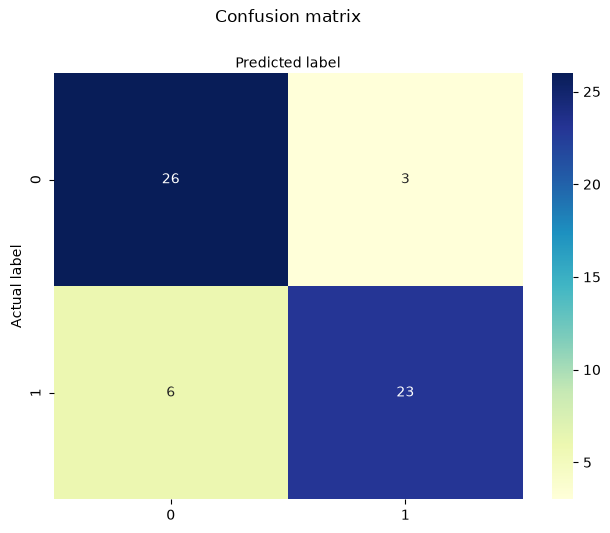

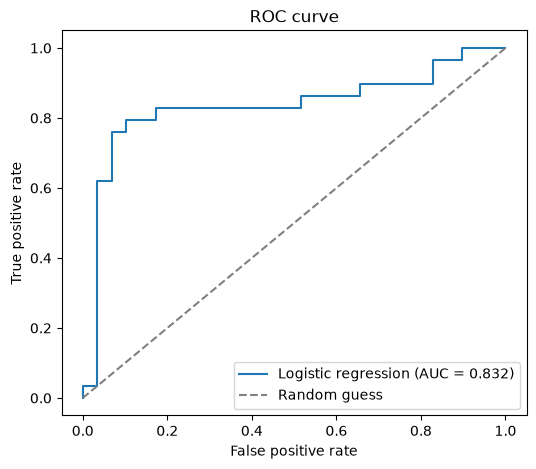

In [14]:
class_names=[0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
# create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')


y_pred_proba = scaled_logreg_model.predict_proba(X_test)[:, 1]   
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)   # false alarm rate and hit rate at every cut-off
auc = roc_auc_score(y_test, y_pred_proba)   # one number for the whole curve

plt.figure(figsize=(6, 5))   # make the picture a fixed size
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {auc:.3f})")   # real label, rounded AUC
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")   # the line a coin flip would make
plt.xlabel("False positive rate")   # axis name
plt.ylabel("True positive rate")   # name of the axis
plt.title("ROC curve")   
plt.legend(loc="lower right")   # show the labels in the bottom right
plt.show()   # show the picture

## References

1. Data camp Understanding Logistic Regression in Python - https://www.datacamp.com/datalab/w/11b0dd9d-49be-429d-992e-45f73b3c23fb#understanding-logistic-regression-in-python 
2. Scikit-learn: LogisticRegression - https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
3. Statistics Calculator - Regression:  https://numiqo.com/statistics-calculator/regression